<a href="https://colab.research.google.com/github/harleenk2295-cpu/c-practice/blob/main/acc%2Ckfold.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from scipy.stats import zscore


data = pd.read_csv('/content/archive (3).zip')

X = data.drop('target',axis=1)
y = data['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

normalization_methods = {
    'MinMaxScaler': MinMaxScaler(),
    'Z-score': StandardScaler(),
    'Decimal Scaling': None,  # Custom implementation
    'Logarithmic Normalization': None,  # Custom implementation
    'Root Transformation': None  # Custom implementation
}

accuracies = {}

for method, scaler in normalization_methods.items():
    X_train_scaled, X_test_scaled = X_train.copy(), X_test.copy()

    if method == 'MinMaxScaler':
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)
    elif method == 'Z-score':
        X_train_scaled = zscore(X_train)
        X_test_scaled = zscore(X_test)
    elif method == 'Decimal Scaling':
        X_train_scaled = X_train / (10 ** np.ceil(np.log10(X_train.abs().max(axis=0))))
        X_test_scaled = X_test / (10 ** np.ceil(np.log10(X_test.abs().max(axis=0))))
    elif method == 'Logarithmic Normalization':
        X_train_scaled = np.log1p(X_train)  # log(1 + x)
        X_test_scaled = np.log1p(X_test)
    elif method == 'Root Transformation':
        X_train_scaled = np.sqrt(X_train)
        X_test_scaled = np.sqrt(X_test)


    models = {
        'Naive Bayes': GaussianNB(),
        'Logistic Regression': LogisticRegression(max_iter=200)
    }

    for model_name, model in models.items():
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        accuracy = accuracy_score(y_test, y_pred)

        accuracies[(method, model_name)] = accuracy

for (norm_method, model_name), accuracy in accuracies.items():
    print(f"Accuracy for {norm_method} with {model_name}: {accuracy:.4f}")

Accuracy for MinMaxScaler with Naive Bayes: 0.8197
Accuracy for MinMaxScaler with Logistic Regression: 0.8033
Accuracy for Z-score with Naive Bayes: 0.8197
Accuracy for Z-score with Logistic Regression: 0.8033
Accuracy for Decimal Scaling with Naive Bayes: 0.5902
Accuracy for Decimal Scaling with Logistic Regression: 0.7377
Accuracy for Logarithmic Normalization with Naive Bayes: 0.7869
Accuracy for Logarithmic Normalization with Logistic Regression: 0.8033
Accuracy for Root Transformation with Naive Bayes: 0.7541
Accuracy for Root Transformation with Logistic Regression: 0.8197


In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load heart dataset (assumed to be in CSV format)
data = pd.read_csv('/content/archive (3).zip')

# Assuming the last column is the target variable
X = data.drop('target', axis=1).values  # Features as a numpy array
y = data['target'].values  # Target variable as a numpy array

# Number of folds for K-Fold Cross-Validation
k = 30

# Store the best accuracies and corresponding folds for both classifiers
best_results = {
    'Naive Bayes': {'max_accuracy': 0, 'fold': 0},
    'Logistic Regression': {'max_accuracy': 0, 'fold': 0}
}

# K-Fold Cross-Validation
kf = KFold(n_splits=k, shuffle=True, random_state=42)

for fold, (train_index, test_index) in enumerate(kf.split(X), start=1):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Naive Bayes Classifier
    bayes_model = GaussianNB()
    bayes_model.fit(X_train, y_train)
    y_pred_bayes = bayes_model.predict(X_test)
    bayes_accuracy = accuracy_score(y_test, y_pred_bayes)

    # Update max accuracy for Naive Bayes
    if bayes_accuracy > best_results['Naive Bayes']['max_accuracy']:
        best_results['Naive Bayes']['max_accuracy'] = bayes_accuracy
        best_results['Naive Bayes']['fold'] = fold

    # Logistic Regression Classifier
    logistic_model = LogisticRegression(max_iter=2000)
    logistic_model.fit(X_train, y_train)
    y_pred_logistic = logistic_model.predict(X_test)
    logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

    # Update max accuracy for Logistic Regression
    if logistic_accuracy > best_results['Logistic Regression']['max_accuracy']:
        best_results['Logistic Regression']['max_accuracy'] = logistic_accuracy
        best_results['Logistic Regression']['fold'] = fold

# Print best results
print(f"Best accuracy of Naive Bayes: {best_results['Naive Bayes']['max_accuracy']:.4f} in fold {best_results['Naive Bayes']['fold']}")
print(f"Best accuracy of Logistic Regression: {best_results['Logistic Regression']['max_accuracy']:.4f} in fold {best_results['Logistic Regression']['fold']}")

Best accuracy of Naive Bayes: 1.0000 in fold 5
Best accuracy of Logistic Regression: 1.0000 in fold 6


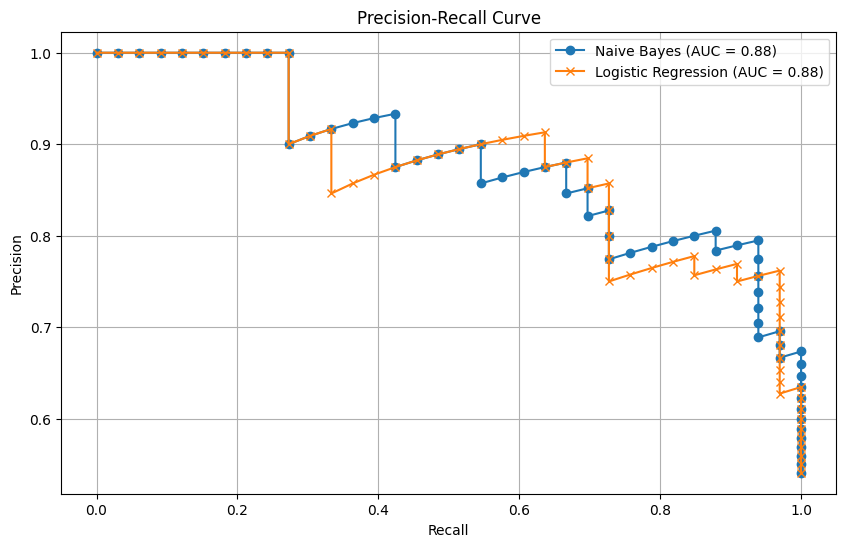

In [40]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_recall_curve, auc

# Load the heart disease dataset
data = pd.read_csv('/content/archive (3).zip')

# Split into features and target
X = data.drop('target', axis=1)
y = data['target']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Initialize classifiers
bayes_model = GaussianNB()

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=10000, solver='lbfgs')
)

# Train Naive Bayes classifier
bayes_model.fit(X_train, y_train)
y_scores_bayes = bayes_model.predict_proba(X_test)[:, 1]

# Train Logistic Regression classifier
logistic_model.fit(X_train, y_train)
y_scores_logistic = logistic_model.predict_proba(X_test)[:, 1]

# Calculate precision and recall for Naive Bayes
precision_bayes, recall_bayes, _ = precision_recall_curve(
    y_test, y_scores_bayes
)
pr_auc_bayes = auc(recall_bayes, precision_bayes)

# Calculate precision and recall for Logistic Regression
precision_logistic, recall_logistic, _ = precision_recall_curve(
    y_test, y_scores_logistic
)
pr_auc_logistic = auc(recall_logistic, precision_logistic)

# Plot the precision-recall curves
plt.figure(figsize=(10, 6))

plt.plot(
    recall_bayes, precision_bayes,
    marker='o',
    label=f'Naive Bayes (AUC = {pr_auc_bayes:.2f})'
)

plt.plot(
    recall_logistic, precision_logistic,
    marker='x',
    label=f'Logistic Regression (AUC = {pr_auc_logistic:.2f})'
)

# Plot settings
plt.title('Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.grid()
plt.show()


In [41]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

data = pd.read_csv('/content/archive (13).zip')

# Separate features and target
X = data.drop('quality', axis=1)
y = data['quality']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalization methods
normalization_methods = {
    'MinMaxScaler': MinMaxScaler(),
    'Z-score': StandardScaler(),
    'Decimal Scaling': None,
    'Logarithmic Normalization': None,
    'Root Transformation': None
}

accuracies = {}

for method, scaler in normalization_methods.items():

    X_train_scaled = X_train.copy()
    X_test_scaled = X_test.copy()

    if method == 'MinMaxScaler':
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

    elif method == 'Z-score':
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

    elif method == 'Decimal Scaling':
        scale = 10 ** np.ceil(
            np.log10(X_train.abs().max().replace(0, 1))
        )
        X_train_scaled = X_train / scale
        X_test_scaled = X_test / scale

    elif method == 'Logarithmic Normalization':
        # Shift features if negative values exist
        shift = (-X_train.min()).clip(lower=0)
        X_train_scaled = np.log1p(X_train + shift)
        X_test_scaled = np.log1p(X_test + shift)

    elif method == 'Root Transformation':
        # Shift features to avoid square roots of negative values
        shift = (-X_train.min()).clip(lower=0)
        X_train_scaled = np.sqrt(X_train + shift)
        X_test_scaled = np.sqrt(X_test + shift)

    # Define models
    models = {
        'Naive Bayes': GaussianNB(),
        'Logistic Regression': LogisticRegression(
            max_iter=10000,
            solver='lbfgs'
        )
    }

    # Train and evaluate models
    for model_name, model in models.items():

        model.fit(X_train_scaled, y_train)

        y_pred = model.predict(X_test_scaled)

        accuracy = accuracy_score(y_test, y_pred)

        accuracies[(method, model_name)] = accuracy

# Display results
for (norm_method, model_name), accuracy in accuracies.items():
    print(
        f"Accuracy for {norm_method} with {model_name}: "
        f"{accuracy:.4f}"
    )


Accuracy for MinMaxScaler with Naive Bayes: 0.5633
Accuracy for MinMaxScaler with Logistic Regression: 0.6201
Accuracy for Z-score with Naive Bayes: 0.5633
Accuracy for Z-score with Logistic Regression: 0.6288
Accuracy for Decimal Scaling with Naive Bayes: 0.5633
Accuracy for Decimal Scaling with Logistic Regression: 0.5459
Accuracy for Logarithmic Normalization with Naive Bayes: 0.6201
Accuracy for Logarithmic Normalization with Logistic Regression: 0.6419
Accuracy for Root Transformation with Naive Bayes: 0.6070
Accuracy for Root Transformation with Logistic Regression: 0.6507


In [42]:

import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Load the dataset
data = pd.read_csv('/content/archive (13).zip')

# Separate features and target
X = data.drop('quality', axis=1).values
y = data['quality'].values

# Number of folds
k = 30

# Store the best accuracies and folds
best_results = {
    'Naive Bayes': {'max_accuracy': 0, 'fold': 0},
    'Logistic Regression': {'max_accuracy': 0, 'fold': 0}
}

# K-Fold Cross-Validation
kf = KFold(n_splits=k, shuffle=True, random_state=42)

for fold, (train_index, test_index) in enumerate(kf.split(X), start=1):

    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Naive Bayes Classifier
    bayes_model = GaussianNB()
    bayes_model.fit(X_train, y_train)

    y_pred_bayes = bayes_model.predict(X_test)
    bayes_accuracy = accuracy_score(y_test, y_pred_bayes)

    if bayes_accuracy > best_results['Naive Bayes']['max_accuracy']:
        best_results['Naive Bayes']['max_accuracy'] = bayes_accuracy
        best_results['Naive Bayes']['fold'] = fold

    # Scale features for Logistic Regression
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Logistic Regression Classifier
    logistic_model = LogisticRegression(max_iter=10000)
    logistic_model.fit(X_train_scaled, y_train)

    y_pred_logistic = logistic_model.predict(X_test_scaled)
    logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

    if logistic_accuracy > best_results['Logistic Regression']['max_accuracy']:
        best_results['Logistic Regression']['max_accuracy'] = logistic_accuracy
        best_results['Logistic Regression']['fold'] = fold

# Print best results
print(
    f"Best accuracy of Naive Bayes: "
    f"{best_results['Naive Bayes']['max_accuracy']:.4f} "
    f"in fold {best_results['Naive Bayes']['fold']}"
)

print(
    f"Best accuracy of Logistic Regression: "
    f"{best_results['Logistic Regression']['max_accuracy']:.4f} "
    f"in fold {best_results['Logistic Regression']['fold']}"
)


Best accuracy of Naive Bayes: 0.7105 in fold 19
Best accuracy of Logistic Regression: 0.7368 in fold 15


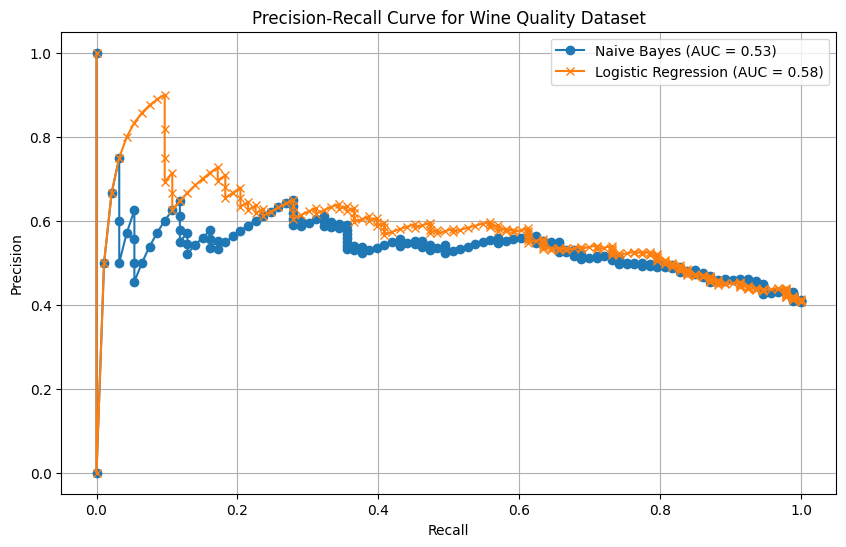

In [53]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, auc
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Load the wine quality dataset
data = pd.read_csv('/content/archive (13).zip')

# Split into features and target
X = data.drop('quality', axis=1)
y = data['quality']

# Select quality 6 as the positive class
positive_class = 6
y_binarized = (y == positive_class).astype(int)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_binarized,
    test_size=0.2,
    random_state=42,
    stratify=y_binarized
)

# Initialize classifiers
bayes_model = make_pipeline(
    StandardScaler(),
    GaussianNB()
)

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=10000, solver='lbfgs')
)

# Train Naive Bayes classifier
bayes_model.fit(X_train, y_train)
y_scores_bayes = bayes_model.predict_proba(X_test)[:, 1]

# Train Logistic Regression classifier
logistic_model.fit(X_train, y_train)
y_scores_logistic = logistic_model.predict_proba(X_test)[:, 1]

# Calculate precision-recall for Naive Bayes
precision_bayes, recall_bayes, _ = precision_recall_curve(
    y_test, y_scores_bayes
)
pr_auc_bayes = auc(recall_bayes, precision_bayes)

# Calculate precision-recall for Logistic Regression
precision_logistic, recall_logistic, _ = precision_recall_curve(
    y_test, y_scores_logistic
)
pr_auc_logistic = auc(recall_logistic, precision_logistic)

# Plot the curves
plt.figure(figsize=(10, 6))

plt.plot(
    recall_bayes,
    precision_bayes,
    marker='o',
    label=f'Naive Bayes (AUC = {pr_auc_bayes:.2f})'
)

plt.plot(
    recall_logistic,
    precision_logistic,
    marker='x',
    label=f'Logistic Regression (AUC = {pr_auc_logistic:.2f})'
)

# Plot settings
plt.title('Precision-Recall Curve for Wine Quality Dataset')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.grid()
plt.show()
